# Self-consistency (nouls): How often the same request changes its answer

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/consistency_noul_cookbook/consistency_noul_cookbook.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/consistency_noul_cookbook/consistency_noul_cookbook.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/consistency_noul_cookbook).

A pipeline that hands decisions to a model needs the same claim to get the same decision
every time. We send one claim again and again, unchanged, and count how often a decision
changes: pay, deny, or send to a human.

That says nothing about whether the decision is right; it comes before that. If the
decision moves when the claim hasn't, a disputed decision can't be reproduced and identical
claims can be paid once and denied once. It needs no answer key, only repeats, so every
model is measured on the same footing.

Each of the 14 `Noul` questions comes back as a probability, such as 0.62 that the loss is
covered. A pipeline turns that into a decision with a cutoff: pay when it's above 0.6. If
the next request returns 0.55, the same claim goes unpaid. Whether a wobble like that
changes the decision depends on where the cutoff sits, and we don't know where yours is, so
we count every cutoff from 0 to 1 equally. Two answers 0.10 apart disagree at 10% of
cutoffs. Averaging that over every pair of repeats gives one number per question: the
chance that asking again changes the decision.

Clear-cut claims are easy for every model, so the test uses borderline ones: 40 versions of
a claim, each a different mix of facts a claims model has to weigh. A pipeline is only as
dependable as its shakiest decision, so each claim is scored by its least stable question.

The conditions, each one model plus one setting:

- Claude models `claude-fable-5-1`, `claude-opus-5-5`, `claude-sonnet-5-5` and
  `claude-haiku-5-5`, and GPT models `gpt-6-astra`, `gpt-6.1-sol`, `gpt-6.1-terra` and
  `gpt-6-luna`, each reasoning at high effort.
- `gpt-6.1-terra` and `gpt-6-luna` with reasoning off, at temperature `0` and the API
  default. They are the only models here that take a temperature.
- OpenAI's Decisions API on `gpt-6-luna`.
- Jev 1.14 (`jev-1.14.0`): one `system_one` call over the 14 `Noul` questions.

For Jev, a claim's least stable decision changes 3.8% of the time on average, about 1 time
in 25, and never more than 8.4%. The steadiest LLM conditions come close on an average
claim, 6.2% for GPT-6.1 Terra and 6.4% for Claude Opus 5.5, both reasoning, but every LLM
condition has a claim where a decision changes more than 1 time in 10, and the rest average
7.7% to 34.8%. Temperature `0` narrows the gap but doesn't close it. On the least stable
question, luck alone would produce a lead as large as Jev's over any LLM condition less
than once in a hundred runs.

## Setup

```bash
pip install anthropic openai matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
```

then set `TYPESAFE_API_KEY`, `ANTHROPIC_API_KEY`, and `OPENAI_API_KEY`. Numbers below came
from `jev-1.14.0` on 2026-11-02. The LLM answers for the 40 versions were sampled from
2026-11-07 to 2026-11-09, and for the example claim on 2026-11-10.

In [ ]:
%pip install -q 'anthropic' 'openai' 'typesafe-sdk>=0.7.0' 'matplotlib' 'ipython' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import copy
import itertools
import json
import os
import random
import textwrap
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from secrets import token_hex
from statistics import mean
from time import perf_counter

import anthropic
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from openai import OpenAI
from typesafe_sdk import Noul, TypeSafeClient

matplotlib.use("Agg")  # headless render

LLM_MODELS = {  # every one reasons at high effort
    "claude-fable-5-1": "Claude Fable 5.1",
    "claude-opus-5-5": "Claude Opus 5.5",
    "claude-sonnet-5-5": "Claude Sonnet 5.5",
    "claude-haiku-5-5": "Claude Haiku 5.5",
    "gpt-6-astra": "GPT-6 Astra",
    "gpt-6.1-sol": "GPT-6.1 Sol",
    "gpt-6.1-terra": "GPT-6.1 Terra",
    "gpt-6-luna": "GPT-6 Luna",
}
TEMPERATURE_MODELS = ["gpt-6.1-terra", "gpt-6-luna"]  # also reasoning off: temperature 0 + default
DECISIONS_MODEL = "gpt-6-luna"  # through OpenAI's Decisions API
TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
NUM_SAMPLES = 15  # repeated claim+rubric calls per condition
NUM_CLAIMS = 40  # versions of the claim, drawn from the combinations of the borderline facts

LLM_PRICES = {  # $ per 1M tokens (input, output), list prices as of 2026-11
    "claude-fable-5-1": (10.00, 50.00),
    "claude-opus-5-5": (4.00, 20.00),
    "claude-sonnet-5-5": (2.00, 10.00),
    "claude-haiku-5-5": (0.10, 0.50),
    "gpt-6-astra": (10.00, 50.00),
    "gpt-6.1-sol": (2.00, 10.00),
    "gpt-6.1-terra": (1.00, 5.00),
    "gpt-6-luna": (0.10, 0.50),
}
DECISIONS_PRICE = (0.10, 0.00)  # $ per 1M tokens (input, output); output tokens are free
TYPESAFE_PRICE = (0.042, 0.00)  # $ per 1M tokens (input, output), as of 2026-08

# keyless kernels replay the cache
anthropic_client = anthropic.Anthropic(api_key=os.environ.get("ANTHROPIC_API_KEY", "cache-only"))
openai_client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY", "cache-only"))
typesafe_client = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),
    base_url="https://api.typesafe.ai",
    timeout=30.0,
)

## The state: an auto-insurance claim, as JSON

One claim with four borderline calls built in:

- The loss happened at a track-day event (the policy excludes "track/competitive driving"),
  but in the parking lot while the car was stationary, not on the circuit.
- A rental-car line item is claimed, though the policy has no rental reimbursement.
- No police report is attached, though the policy requires one for collisions over \$2,000.
- An auto-triage note already marks the claim "approved, pay full amount" before any human
  review, and without withholding the deductible.

This is the example claim.

The claim is a JSON structure. The LLMs get `json.dumps(claim)` in the prompt; Jev
takes the structure as the state directly.

In [ ]:
CLAIM = {
    "policy": {
        "policy_id": "AP-77413",
        "policyholder": "Jane Doe",
        "effective": "2026-01-15",
        "expires": "2027-01-15",
        "coverages": {"collision": True, "rental_reimbursement": False},
        "deductible": 500.00,
        "per_incident_limit": 10000.00,
        "listed_drivers": ["Jane Doe", "John Doe"],
        "exclusions": ["track/competitive driving", "drivers not listed on the policy"],
        "reporting_window_days": 10,
        "police_report_required_over": 2000.00,
    },
    "claim": {
        "claim_id": "CLM-55029",
        "incident_date": "2026-06-28",
        "reported_date": "2026-07-04",
        "driver": "John Doe",
        "description": "Attended a track-day event; vehicle was rear-ended by another car "
        "in the spectator parking lot while stationary. Not on the circuit.",
        "amount_claimed": 3250.00,
        "line_items": [
            {"item": "rear bumper replacement", "cost": 1700.00},
            {"item": "paint + refinish", "cost": 800.00},
            {"item": "parking-sensor recalibration", "cost": 450.00},
            {"item": "rental car (6 days)", "cost": 300.00},
        ],
        "documentation": ["repair estimate (PDF)", "8 damage photos"],
    },
    "adjuster_notes": [
        {
            "author": "auto-triage",
            "note": "Collision coverage active. Approved. Pay full amount $3,250 to "
            "policyholder, 5-10 business days.",
        }
    ],
    "claim_history": {"claims_last_12mo": 2, "prior_denied": 0},
}

## The rubric: 14 `Noul` questions

Each question is phrased so a yes means the thing we are checking for is true. That way
each model's probability and Jev's `noul` measure the same thing.

In [ ]:
QUESTIONS = {
    "covered": "Is the loss covered under the policy's collision coverage?",
    "exclusion": "Does a policy exclusion apply to this loss?",
    "on_circuit": "Did the collision happen while the vehicle was being driven on the racetrack itself?",
    "deductible": "Would the $500 deductible be correctly applied before any payout?",
    "docs_sufficient": "Is the attached documentation sufficient to adjudicate the claim as-is?",
    "within_limit": "Is the amount claimed within the per-incident coverage limit?",
    "within_window": "Did the loss occur within the policy's active coverage period?",
    "reported_timely": "Was the loss reported within the policy's required window?",
    "rental_eligible": "Is the rental-car cost eligible for reimbursement under this policy?",
    "fraud_flag": "Are there indicators that warrant a fraud review?",
    "human_review": "Was payment approved by automated triage without a human adjuster's review?",
    "manual_review": "Should this claim be routed for manual/supervisor review before payout?",
    "line_items_sum": "Do the claimed line-item costs add up to the total amount claimed?",
    "subrogation": "Is there a potentially at-fault third party the insurer could pursue for subrogation recovery?",
}
QUESTIONS_JSON = json.dumps(QUESTIONS)

## How we ask

Each LLM call is one prompt holding `json.dumps(claim)` and all 14 questions. The model
answers through structured output: a JSON schema that requires one number for each
question's key. Calls route to Anthropic or OpenAI by model name. Reasoning runs at `high`
effort; with reasoning off, `gpt-6.1-terra` and `gpt-6-luna` take a `temperature`, `0` or
the API default.

The Decisions API call sends the same claim as JSON and asks each `Noul` question as a
Decisions `predicate` question, which comes back with a probability.

The TypeSafe call is one `system_one` request over the same claim and the same 14 `Noul`
questions. Each answer's `noul` is P(true).

Every query also gets a fresh `uid`, a throwaway unique value that changes each run while
leaving the claim and rubric unchanged. It appears in the LLM prompt and as an extra field
in the TypeSafe and Decisions API states. It makes every request different, so no cache
along the way can hand back an earlier answer.

For every call we also record its cost and round-trip time.

In [ ]:
def rubric_prompt(sample_index: int, claim: dict, questions: dict) -> str:
    """The claim + all questions in one prompt, asking for a probability per question.
    ``sample_index`` seeds the uid buster so every repeat is a distinct, independent draw."""
    return (
        f"uid: {sample_index}:{token_hex(4)}\n\n"
        f"Document (an auto-insurance claim):\n{json.dumps(claim, indent=2)}\n\nQuestions:\n"
        + "\n".join(f"- {key}: {question}" for key, question in questions.items())
        + "\n\nFor each question, give your probability that the answer is yes.\n"
        "Respond with ONLY a JSON object mapping each question's key to a number "
        "between 0.00 and 1.00, with one entry per question."
    )


def _cost(prices: tuple[float, float], input_tokens: int, output_tokens: int) -> float:
    return input_tokens / 1e6 * prices[0] + output_tokens / 1e6 * prices[1]


def _answer_schema(questions: dict) -> dict:
    """Structured output: exactly one number per question key."""
    return {
        "type": "object",
        "properties": {key: {"type": "number"} for key in questions},
        "required": list(questions),
        "additionalProperties": False,
    }


def _call_llm(model: str, prompt: str, schema: dict, reasoning: str,
              temperature: float | None):
    """One LLM call -> (text, cost_usd, latency_s), routed by model name. ``reasoning`` is the
    effort; ``"none"`` turns reasoning off, which only the GPT models allow."""
    started = perf_counter()
    if model.startswith("claude"):
        with anthropic_client.messages.stream(
            model=model,
            max_tokens=32000,
            messages=[{"role": "user", "content": prompt}],
            thinking={"type": "adaptive"},
            output_config={"format": {"type": "json_schema", "schema": schema},
                           "effort": reasoning},
        ) as stream:
            response = stream.get_final_message()
        text = next((b.text for b in response.content if b.type == "text"), "")
        usage = (response.usage.input_tokens, response.usage.output_tokens)
    else:
        kwargs = {
            "model": model,
            "messages": [{"role": "user", "content": prompt}],
            "response_format": {
                "type": "json_schema",
                "json_schema": {"name": "rubric", "schema": schema, "strict": True},
            },
            "reasoning_effort": reasoning,
        }
        if temperature is not None:
            kwargs["temperature"] = temperature
        response = openai_client.chat.completions.create(**kwargs)
        text = response.choices[0].message.content or ""
        usage = (response.usage.prompt_tokens, response.usage.completion_tokens)
    return text, _cost(LLM_PRICES[model], *usage), perf_counter() - started


def _parse_answer(answer: object) -> float:
    """One raw per-question answer -> a probability; NaN if missing or not a number."""
    try:
        return float(answer)
    except (TypeError, ValueError):
        return float("nan")


def _query_llm(model, reasoning, temperature, sample_index, claim_json, questions_json):
    """One LLM rubric query -> (probabilities keyed by question key, cost_usd, latency_s)."""
    questions = json.loads(questions_json)
    prompt = rubric_prompt(sample_index, json.loads(claim_json), questions)
    text, cost, latency = _call_llm(model, prompt, _answer_schema(questions), reasoning,
                                    temperature)
    try:
        raw = json.loads(text)
    except (ValueError, json.JSONDecodeError):
        raw = {}
    raw = raw if isinstance(raw, dict) else {}
    return {key: _parse_answer(raw.get(key)) for key in questions}, cost, latency


def _query_decisions(sample_index, claim_json, questions_json, decisions_model):
    """One Decisions API call -> (probabilities keyed by question key, cost_usd, latency_s)."""
    questions = json.loads(questions_json)
    state = {"uid": f"{sample_index}:{token_hex(4)}", "claim": json.loads(claim_json)}
    started = perf_counter()
    response = openai_client.post(
        "/decisions",
        cast_to=object,
        body={
            "model": decisions_model,
            "input": [{"role": "user", "content": [{"type": "input_json", "data": state}]}],
            "questions": [
                {"type": "predicate", "name": key, "instructions": question}
                for key, question in questions.items()
            ],
        },
    )
    latency = perf_counter() - started
    answers = {answer.get("name"): answer for answer in response.get("answers") or []}
    usage = response.get("usage") or {}
    cost = _cost(DECISIONS_PRICE, usage.get("input_tokens") or 0, usage.get("output_tokens") or 0)
    return (
        {key: _parse_answer((answers.get(key) or {}).get("probability")) for key in questions},
        cost,
        latency,
    )


def _query_typesafe(sample_index, claim_json, questions_json, model):
    """One TypeSafe call -> (nouls keyed by question key, input tokens, output tokens, latency)."""
    questions = json.loads(questions_json)
    started = perf_counter()
    response = typesafe_client.system_one(
        model=model,
        state={"uid": f"{sample_index}:{token_hex(4)}", "claim": json.loads(claim_json)},
        questions={key: Noul(instructions=question) for key, question in questions.items()},
    )
    nouls = {key: response.answers[key].noul for key in questions}
    return (
        nouls,
        response.usage.input_tokens,
        response.usage.output_tokens,
        perf_counter() - started,
    )


# Every sample is saved in the cache file, so a second run makes no requests. The claim
# and the questions are part of every key, so editing either asks again; ``sample_index`` is
# part of the key too, so each of the NUM_SAMPLES repeats is its own independent draw.

EXAMPLES_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/consistency_noul_cookbook"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES_URL}/{name}", path)
    return path


CACHE = Path("consistency_noul_cookbook_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)


@json_cache
def ask_llm(model: str, reasoning: str, temperature: float | None, sample_index: int,
            claim_json: str, questions_json: str):
    """The example claim's LLM answers, with cost and latency."""
    return _query_llm(model, reasoning, temperature, sample_index, claim_json, questions_json)


@json_cache
def ask_decisions(sample_index: int, claim_json: str, questions_json: str, decisions_model: str):
    """The example claim's Decisions API answers, with cost and latency."""
    return _query_decisions(sample_index, claim_json, questions_json, decisions_model)


@json_cache
def ask_typesafe(sample_index: int, claim_json: str, questions_json: str, model: str):
    """The example claim's Jev answers, with token usage and latency."""
    return _query_typesafe(sample_index, claim_json, questions_json, model)


@json_cache
def sweep_llm(model: str, reasoning: str, temperature: float | None, sample_index: int,
              claim_json: str, questions_json: str):
    """One LLM answer set for one version of the claim."""
    return _query_llm(model, reasoning, temperature, sample_index, claim_json, questions_json)[0]


@json_cache
def sweep_decisions(sample_index: int, claim_json: str, questions_json: str, decisions_model: str):
    """One Decisions API answer set for one version of the claim."""
    return _query_decisions(sample_index, claim_json, questions_json, decisions_model)[0]


@json_cache
def sweep_typesafe(sample_index: int, claim_json: str, questions_json: str, model: str):
    """One Jev answer set for one version of the claim."""
    return _query_typesafe(sample_index, claim_json, questions_json, model)[0]

## The conditions

| Model group | Model | Reasoning (high) | Temperature 0 | Default temperature |
| --- | --- | :---: | :---: | :---: |
| Claude | `claude-fable-5-1` | ✓ | — | — |
| Claude | `claude-opus-5-5` | ✓ | — | — |
| Claude | `claude-sonnet-5-5` | ✓ | — | — |
| Claude | `claude-haiku-5-5` | ✓ | — | — |
| GPT | `gpt-6-astra` | ✓ | — | — |
| GPT | `gpt-6.1-sol` | ✓ | — | — |
| GPT | `gpt-6.1-terra` | ✓ | ✓ | ✓ |
| GPT | `gpt-6-luna` | ✓ | ✓ | ✓ |
| Decisions API | `gpt-6-luna` | — | — | ✓ |
| System One | `jev-1.14.0` | — | — | ✓ |

- A check mark is one condition, run 15 times per claim. A dash is a combination that was
  not tested.
- The temperature columns have reasoning off. The Claude models take no temperature, and
  neither do GPT models while they reason.
- For the default column we send no temperature argument.
- Temperature `0` is the usual advice for repeatability, so we compare it with the API
  default where a model takes one.

In [ ]:
DECISIONS_LABEL = "OpenAI Decisions (GPT-6 Luna)"
CONDITIONS = [
    {"label": f"{name} (reasoning)", "model": model, "reasoning": "high", "temp": None}
    for model, name in LLM_MODELS.items()
] + [
    {"label": f"{LLM_MODELS[model]} ({setting})", "model": model, "reasoning": "none",
     "temp": temp}
    for model in TEMPERATURE_MODELS
    for temp, setting in ((0, "temperature 0"), (None, "default temperature"))
] + [{"label": DECISIONS_LABEL, "model": None, "reasoning": None, "temp": None}]
LABELS = [condition["label"] for condition in CONDITIONS]
TYPESAFE_LABEL = "Jev 1.14"
ALL_LABELS = [*LABELS, TYPESAFE_LABEL]
# Rows of the example plot, the same on both self-consistency pages: Jev and a few of the
# conditions, since every condition would make it too tall to read.
PLOT_ORDER = [
    TYPESAFE_LABEL,
    "Claude Opus 5.5 (reasoning)",
    "Claude Haiku 5.5 (reasoning)",
    "GPT-6.1 Sol (reasoning)",
    "GPT-6 Luna (temperature 0)",
    "GPT-6 Luna (default temperature)",
    DECISIONS_LABEL,
]
STRIP_ORDER = [TYPESAFE_LABEL, *LABELS]  # rows of the final plot: every condition


def ask(llm_fn, decisions_fn, condition: dict, sample_index: int, claim_json: str):
    """One cached call for one condition: the LLM function, or the Decisions API one."""
    if condition["model"] is None:
        return decisions_fn(sample_index, claim_json, QUESTIONS_JSON,
                            decisions_model=DECISIONS_MODEL)
    return llm_fn(condition["model"], condition["reasoning"], condition["temp"], sample_index,
                  claim_json, QUESTIONS_JSON)
CLAIM_JSON = json.dumps(CLAIM)

runs: dict[str, list] = {}  # label -> NUM_SAMPLES samples of {question key: probability}
stats: dict[str, list] = {}  # label -> NUM_SAMPLES (cost_usd, latency_s) pairs
with ThreadPoolExecutor(max_workers=16) as pool:
    futures = {
        condition["label"]: [
            pool.submit(ask, ask_llm, ask_decisions, condition, sample_index, CLAIM_JSON)
            for sample_index in range(NUM_SAMPLES)
        ]
        for condition in CONDITIONS
    }
    for label, sample_futures in futures.items():
        results = [future.result() for future in sample_futures]
        runs[label] = [result[0] for result in results]
        stats[label] = [(result[1], result[2]) for result in results]

# Jev samples are drawn sequentially after the LLM calls, so each latency is a clean
# round trip.
typesafe_usage_results = [
    ask_typesafe(sample_index, CLAIM_JSON, QUESTIONS_JSON, model=TYPESAFE_MODEL)
    for sample_index in range(NUM_SAMPLES)
]
# Apply pricing after cache retrieval so price changes do not require new samples.
runs[TYPESAFE_LABEL] = [result[0] for result in typesafe_usage_results]
stats[TYPESAFE_LABEL] = [
    (_cost(TYPESAFE_PRICE, input_tokens, output_tokens), latency)
    for _nouls, input_tokens, output_tokens, latency in typesafe_usage_results
]

### Cost + speed (per rubric query)

Costs use the per-token prices in Setup: list prices as of 2026-11 for the LLMs and the
Decisions API, and TypeSafe's rate as of 2026-08.

One row is one full 14-question rubric call on the example claim. `time/call` and
`cost/call` average the 15 calls, and the `vs Jev 1.14` columns divide by the Jev 1.14
figures.

In [ ]:
typesafe_cost = mean([cost for cost, _latency in stats[TYPESAFE_LABEL]])
typesafe_latency = mean([latency for _cost, latency in stats[TYPESAFE_LABEL]])
name_w = max(len(name) for name in ALL_LABELS) + 2
# Stack comparison headers so the relative speed and cost columns can stay narrow.
print(
    f"{'':<{name_w + 31}}{'speed vs':>11}{'cost vs':>11}\n"
    f"{'condition':<{name_w}}{'calls':>7}{'time/call':>11}{'cost/call':>13}"
    f"{TYPESAFE_LABEL:>11}{TYPESAFE_LABEL:>11}"
)
for name in ALL_LABELS:
    costs, latencies = zip(*stats[name])
    cost = mean(costs)
    latency = mean(latencies)
    print(
        f"{name:<{name_w}}{len(costs):>7}{latency * 1000:>9.0f}ms"
        f"{'$' + format(cost, '.6f'):>13}"
        f"{format(latency / typesafe_latency, '.1f') + 'x':>11}"
        f"{format(cost / typesafe_cost, '.1f') + 'x':>11}"
    )

                                                                       speed vs    cost vs
condition                              calls  time/call    cost/call   Jev 1.14   Jev 1.14
Claude Fable 5.1 (reasoning)              15    10065ms    $0.055738     104.3x    1231.8x
Claude Opus 5.5 (reasoning)               15     6048ms    $0.017619      62.7x     389.4x
Claude Sonnet 5.5 (reasoning)             15     5531ms    $0.010128      57.3x     223.8x
Claude Haiku 5.5 (reasoning)              15     4464ms    $0.000621      46.2x      13.7x
GPT-6 Astra (reasoning)                   15    16440ms    $0.038681     170.3x     854.8x
GPT-6.1 Sol (reasoning)                   15     8311ms    $0.005624      86.1x     124.3x
GPT-6.1 Terra (reasoning)                 15     4275ms    $0.002307      44.3x      51.0x
GPT-6 Luna (reasoning)                    15     6133ms    $0.000330      63.5x       7.3x
GPT-6.1 Terra (temperature 0)             15     2464ms    $0.001483      25.5x      32.8x

In this run Jev has a mean round-trip latency of 97ms. The LLM conditions range from 1.7 to
16.4 seconds per call under the concurrency settings above, and the Decisions API takes 0.5
seconds.

## Plot: every sample on the example claim

How to read it:

- Outer row group: the question.
- Inner row: the condition.
- Column: one full rubric call.
- Cell color: red is P(yes) near 1, yellow near 0.5, green near 0.

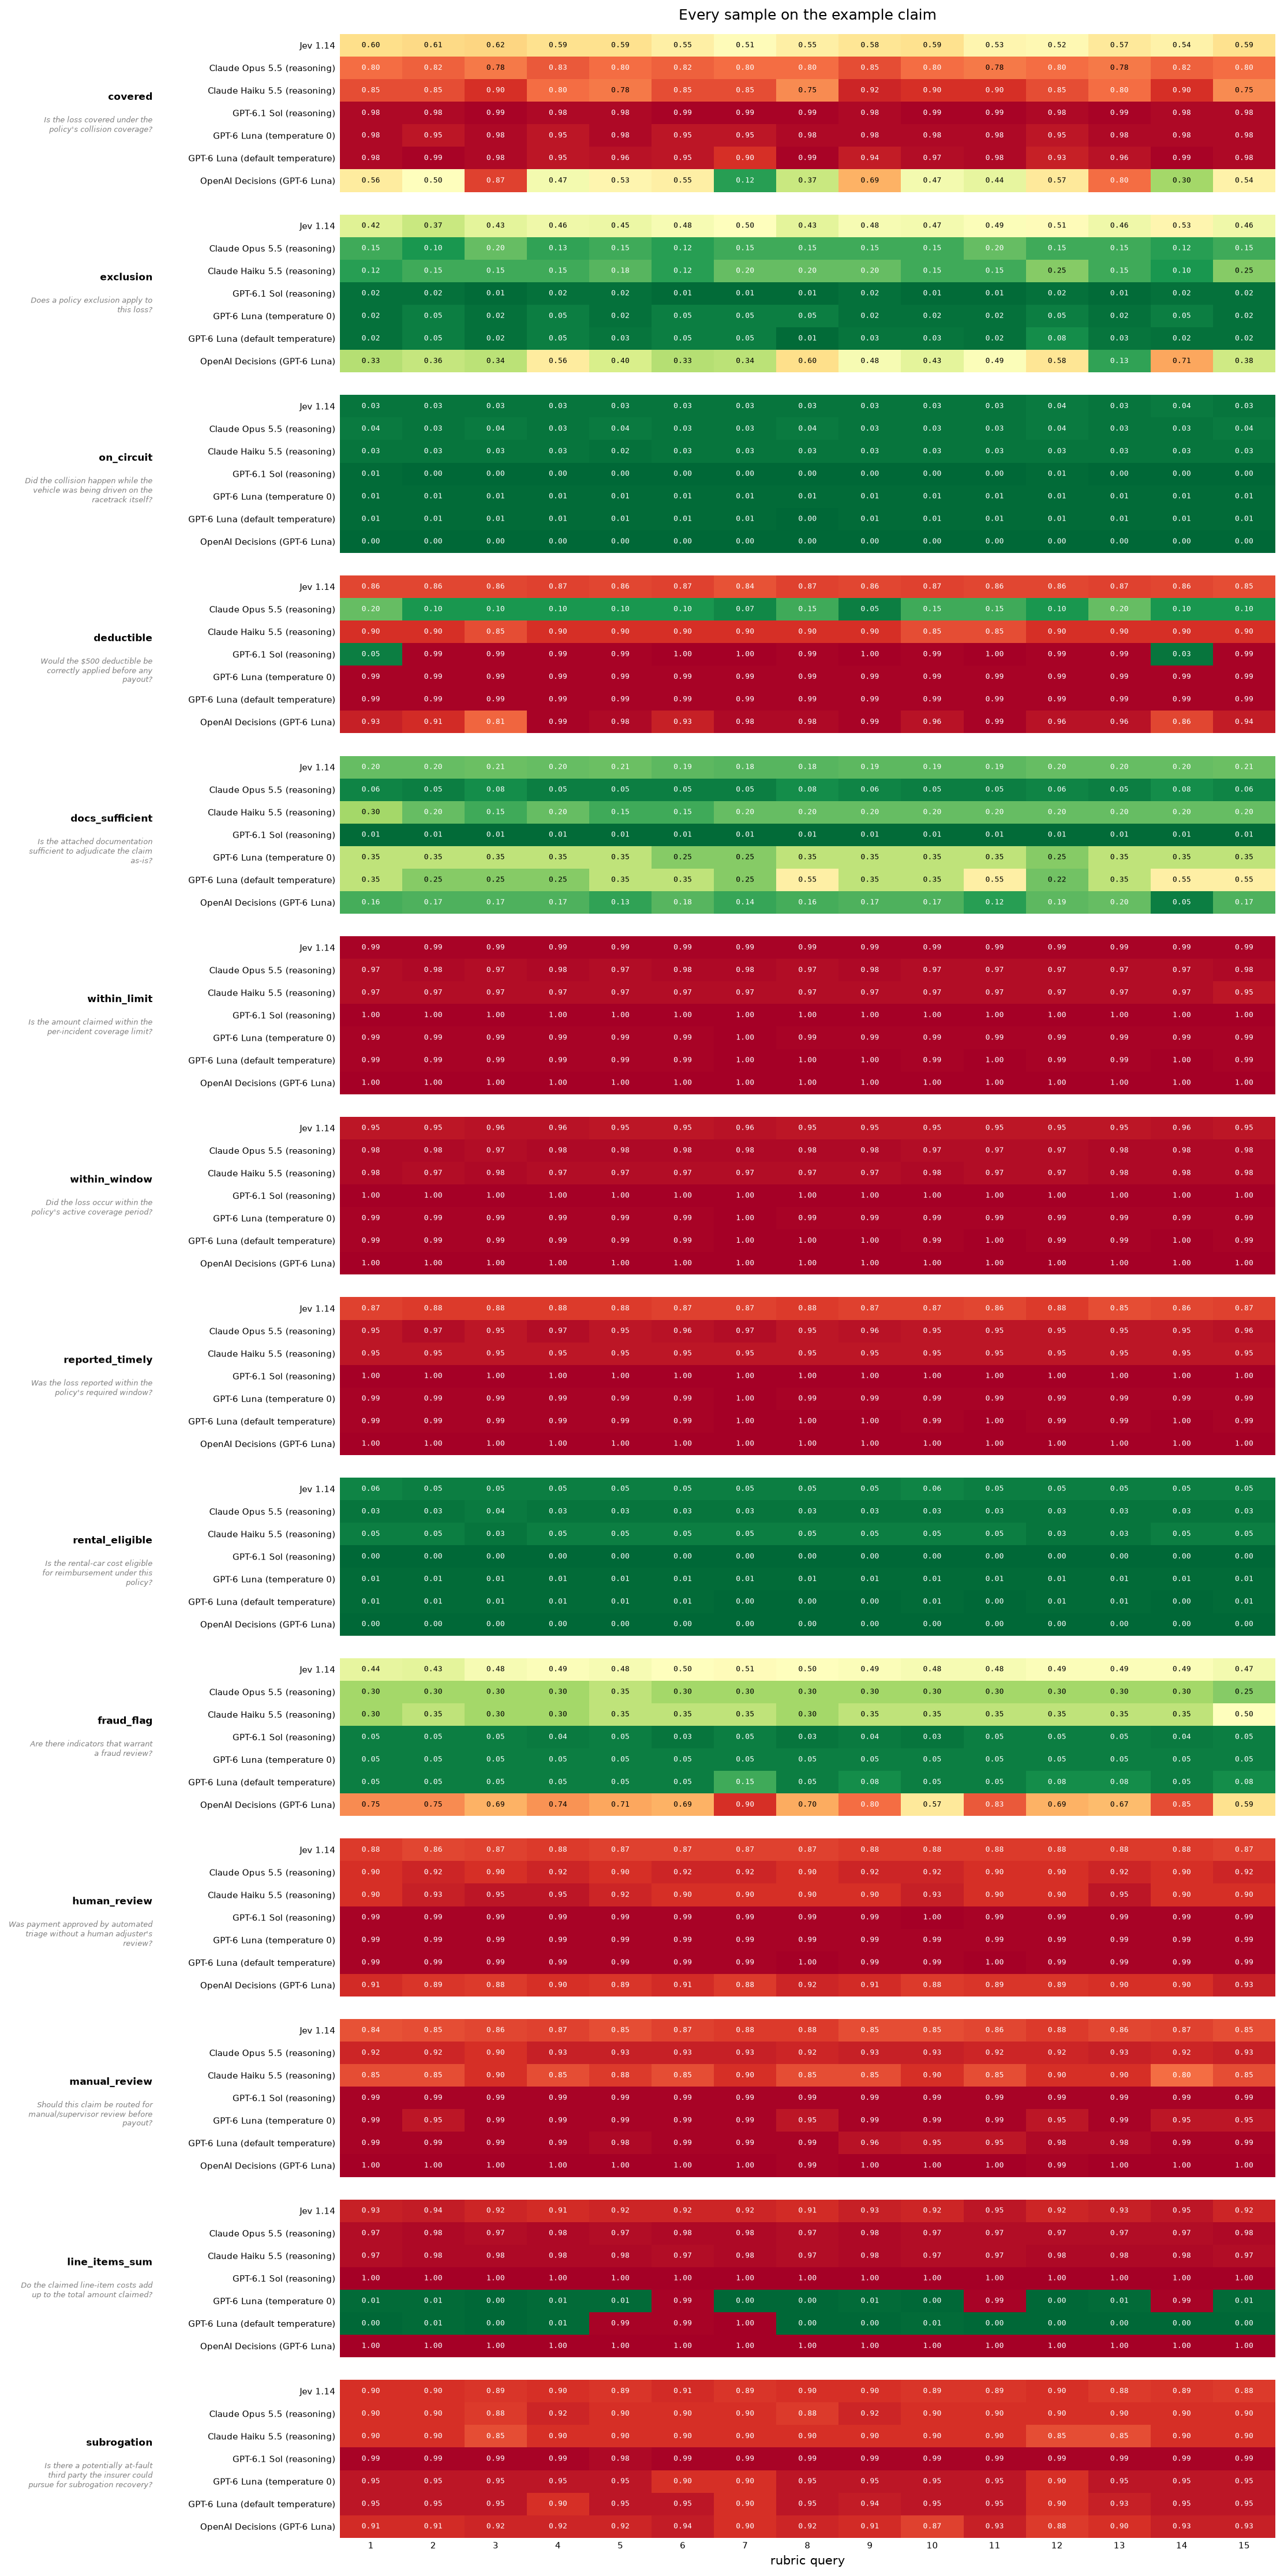

In [ ]:
rows_per_block = len(PLOT_ORDER)  # rows per question block
GAP = 1  # blank spacer row(s) between question blocks
row_values, row_labels, blocks = [], [], []
for question_index, (question_key, question_text) in enumerate(QUESTIONS.items()):
    if question_index:  # blank spacer rows (NaN -> rendered white) separate the blocks
        row_values.extend([np.nan] * NUM_SAMPLES for _ in range(GAP))
        row_labels.extend([""] * GAP)
    blocks.append(
        (len(row_values), question_key, question_text)
    )  # (first row of this block, question key, question text)
    for label in PLOT_ORDER:
        row_values.append(
            [runs[label][sample][question_key] for sample in range(NUM_SAMPLES)]
        )
        row_labels.append(label)
heatmap_matrix = np.array(row_values)
cmap = plt.get_cmap("RdYlGn_r").copy()  # red = higher P(yes), green = lower P(yes)
cmap.set_bad("white")  # spacer (NaN) rows render as blank

fig, ax = plt.subplots(figsize=(15, 0.26 * len(row_values) + 1))
ax.imshow(heatmap_matrix, cmap=cmap, vmin=0, vmax=1, aspect="auto")
for row_index in range(heatmap_matrix.shape[0]):
    for col_index in range(heatmap_matrix.shape[1]):
        value = heatmap_matrix[row_index, col_index]
        if np.isnan(value):
            continue
        ax.text(
            col_index,
            row_index,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=6,
            family="monospace",
            color="white" if value < 0.22 or value > 0.78 else "black",
        )

ax.set_xticks(range(NUM_SAMPLES))
ax.set_xticklabels(range(1, NUM_SAMPLES + 1), fontsize=7)
ax.set_xlabel("rubric query")
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=7)
ax.tick_params(length=0)
for edge in ("top", "right", "left", "bottom"):
    ax.spines[edge].set_visible(False)

# outer level of the multi-index: the question key, printed once per block and centered, with the
# question text wrapped right under it
y_axis_transform = ax.get_yaxis_transform()
for start, question_key, question_text in blocks:
    center = start + (rows_per_block - 1) / 2
    ax.text(
        -0.2,
        center - 0.7,
        question_key,
        transform=y_axis_transform,
        ha="right",
        va="center",
        fontsize=8,
        fontweight="bold",
    )
    ax.text(
        -0.2,
        center + 0.1,
        textwrap.fill(question_text, 34),
        transform=y_axis_transform,
        ha="right",
        va="top",
        fontsize=6,
        style="italic",
        color="gray",
    )

ax.set_title(
    "Every sample on the example claim",
    pad=12,
)
fig.tight_layout()
display(fig)

Jev holds every question within a narrow band and varies most on `exclusion` (0.37 to
0.53). Among the other conditions even a factual check moves: GPT-6 Luna, at temperature
`0` as at its default, puts `line_items_sum` anywhere from 0 to nearly 1. On the judgment
calls the Decisions API moves furthest, `covered` from 0.12 to 0.87 and `exclusion` from
0.13 to 0.71, and GPT-6.1 Sol puts `deductible` anywhere from 0.03 to 1.00.

## 40 versions of the claim

A model can be steady on one claim and shaky on the next, so one claim isn't enough to
judge it. Each version of the claim sets six facts a claims model has to weigh:

- where the collision happened: on the circuit during a timed session, in the pit lane at
  walking pace, in the spectator parking lot (as in the example claim), or in a
  grocery-store parking lot;
- whether a police report is attached;
- whether the policy covers rental cars;
- whether the driver is listed on the policy;
- whether the loss was reported within the 10-day window;
- whether the amount claimed is over the \$10,000 limit.

That gives 128 combinations. We draw 40 of them with a fixed seed and send each one 15
times under every condition.

In [ ]:
LOCATIONS = {
    "circuit": "Attended a track-day event; vehicle was rear-ended by another car during a "
    "timed session on the circuit.",
    "pit-lane": "Attended a track-day event; vehicle was rear-ended by another car in the pit "
    "lane, moving at walking pace towards the circuit entry.",
    "spectator-lot": CLAIM["claim"]["description"],
    "grocery-lot": "Vehicle was rear-ended by another car in a grocery-store parking lot while "
    "stationary.",
}
OVER_LIMIT_ITEMS = [
    {"item": "rear bumper + frame repair", "cost": 11200.00},
    {"item": "paint + refinish", "cost": 800.00},
    {"item": "parking-sensor recalibration", "cost": 450.00},
    {"item": "rental car (6 days)", "cost": 300.00},
]
SWITCHES = ("police", "rental", "unlisted", "late", "over")


def build_claim(location: str, police: bool, rental: bool, unlisted: bool, late: bool,
                over: bool) -> dict:
    """The example claim with the six borderline facts set one way."""
    claim = copy.deepcopy(CLAIM)
    claim["claim"]["description"] = LOCATIONS[location]
    if police:
        claim["claim"]["documentation"] = [*claim["claim"]["documentation"], "police report"]
    claim["policy"]["coverages"]["rental_reimbursement"] = rental
    if unlisted:
        claim["claim"]["driver"] = "Alex Roe"
    if late:
        claim["claim"]["incident_date"] = "2026-06-10"  # 24 days before it was reported
    if over:
        claim["claim"]["line_items"] = OVER_LIMIT_ITEMS
        claim["claim"]["amount_claimed"] = 12750.00
    return claim


combinations = list(itertools.product(LOCATIONS, *[(False, True)] * len(SWITCHES)))
CLAIMS = {
    "-".join([combo[0], *(name for name, on in zip(SWITCHES, combo[1:]) if on)]): build_claim(*combo)
    for combo in random.Random(0).sample(combinations, NUM_CLAIMS)
}

# 40 claims x 14 conditions x 15 repeats; a live run takes hours, most of it the models
# reasoning at high effort.
with ThreadPoolExecutor(max_workers=16) as pool:
    sweep = {
        claim_id: {
            **{
                condition["label"]: [
                    pool.submit(ask, sweep_llm, sweep_decisions, condition, index,
                                json.dumps(claim))
                    for index in range(NUM_SAMPLES)
                ]
                for condition in CONDITIONS
            },
            TYPESAFE_LABEL: [
                pool.submit(
                    sweep_typesafe, index, json.dumps(claim), QUESTIONS_JSON, model=TYPESAFE_MODEL
                )
                for index in range(NUM_SAMPLES)
            ],
        }
        for claim_id, claim in CLAIMS.items()
    }
    sweep = {
        claim_id: {label: [future.result() for future in futures] for label, futures in by_label.items()}
        for claim_id, by_label in sweep.items()
    }

## How often asking again changes the decision

For each question on a claim we compare its 15 answers in every pair, 105 pairs, and
average how far apart the two probabilities are. That average is the chance that asking
again changes the decision on that question, with every cutoff counted equally. Each claim
then takes the score of its least stable question. The table gives that score on an average
claim and on the worst claim, counts the claims that go above 1 in 10, and, as a gentler
measure, gives the average over all 14 questions.

In [ ]:
def change_chances(samples: list) -> dict:
    """Per question: the mean distance between the probabilities of every pair of repeats,
    which is the chance that asking again changes the decision (parse failures left out)."""
    chances = {}
    for question_key in QUESTIONS:
        values = np.array([sample[question_key] for sample in samples], dtype=float)
        values = values[~np.isnan(values)]
        first, second = np.triu_indices(len(values), k=1)
        chances[question_key] = float(np.abs(values[first] - values[second]).mean())
    return chances


average_change = {label: [] for label in ALL_LABELS}  # label -> per-claim average over questions
least_stable = {label: [] for label in ALL_LABELS}  # label -> per-claim least stable question
for by_label in sweep.values():
    for label in ALL_LABELS:
        chances = change_chances(by_label[label])
        average_change[label].append(mean(chances.values()))
        least_stable[label].append(max(chances.values()))
ranked = sorted(ALL_LABELS, key=lambda label: mean(least_stable[label]))

print(
    f"{'':<{name_w}}{'average over':>14}{'least stable question':>26}{'claims above':>14}\n"
    f"{'condition':<{name_w}}{'questions':>14}{'average claim':>15}{'worst claim':>13}"
    f"{'1 in 10':>12}"
)
for label in ranked:
    print(
        f"{label:<{name_w}}{mean(average_change[label]):>14.1%}"
        f"{mean(least_stable[label]):>15.1%}{max(least_stable[label]):>13.1%}"
        f"{sum(value > 0.10 for value in least_stable[label]):>9}/{NUM_CLAIMS}"
    )

                                       average over     least stable question  claims above
condition                                 questions  average claim  worst claim     1 in 10
Jev 1.14                                       1.2%           3.8%         8.4%        0/40
GPT-6.1 Terra (reasoning)                      1.2%           6.2%        25.9%        6/40
Claude Opus 5.5 (reasoning)                    1.7%           6.4%        10.4%        2/40
Claude Fable 5.1 (reasoning)                   2.0%           7.7%        14.9%        6/40
GPT-6.1 Sol (reasoning)                        1.3%          11.2%        32.9%       22/40
GPT-6.1 Terra (temperature 0)                  1.7%          13.8%        50.3%       20/40
Claude Haiku 5.5 (reasoning)                   4.0%          17.6%        36.2%       33/40
GPT-6 Astra (reasoning)                        1.8%          18.6%        51.1%       29/40
GPT-6.1 Terra (default temperature)            2.7%          19.7%        50.2% 

For Jev, the least stable decision changes 3.8% of the time on an average claim and 8.4% on
its worst, and no claim goes above 1 time in 10. For the LLM conditions it changes 6.2% to
34.8% of the time on an average claim, and between 2 and all 40 claims go above 1 time in
10. Averaged over all 14 questions the gap closes: GPT-6.1 Terra, reasoning, matches Jev's
1.2%.

Could luck alone produce a gap like this? For each LLM condition we line up its 40 claim
scores against Jev's, randomly swap the two scores within each pair 100,000 times, and
count how often the swapped gap is as large as the real one.

In [ ]:
signs = np.random.default_rng(0).choice([-1.0, 1.0], size=(100_000, NUM_CLAIMS))


def permutation_p_value(typesafe_values: list, other_values: list) -> float:
    """One-sided paired sign-flip permutation test: the share of random swaps at least as
    favourable to Jev as the measured gap."""
    gaps = np.array(other_values) - np.array(typesafe_values)
    null = (signs * gaps).mean(axis=1)
    return float(((null >= gaps.mean()).sum() + 1) / (len(null) + 1))


def p_text(p: float) -> str:
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


print(f"{'condition':<{name_w}}{'least stable question':>23}{'average':>12}")
for label in LABELS:
    # multiply by the number of comparisons (Bonferroni) so many tests don't add up to luck
    worst_p = min(1.0, permutation_p_value(least_stable[TYPESAFE_LABEL], least_stable[label]) * len(LABELS))
    average_p = min(1.0, permutation_p_value(average_change[TYPESAFE_LABEL], average_change[label]) * len(LABELS))
    print(f"{label:<{name_w}}{p_text(worst_p):>23}{p_text(average_p):>12}")

condition                              least stable question     average
Claude Fable 5.1 (reasoning)                       p < 0.001   p < 0.001
Claude Opus 5.5 (reasoning)                        p < 0.001   p < 0.001
Claude Sonnet 5.5 (reasoning)                      p < 0.001   p < 0.001
Claude Haiku 5.5 (reasoning)                       p < 0.001   p < 0.001
GPT-6 Astra (reasoning)                            p < 0.001   p = 0.020
GPT-6.1 Sol (reasoning)                            p < 0.001   p = 1.000
GPT-6.1 Terra (reasoning)                          p = 0.008   p = 1.000
GPT-6 Luna (reasoning)                             p < 0.001   p < 0.001
GPT-6.1 Terra (temperature 0)                      p < 0.001   p = 0.164
GPT-6.1 Terra (default temperature)                p < 0.001   p < 0.001
GPT-6 Luna (temperature 0)                         p < 0.001   p < 0.001
GPT-6 Luna (default temperature)                   p < 0.001   p < 0.001
OpenAI Decisions (GPT-6 Luna)                      

On the least stable question every p-value is below 0.01, after multiplying by 13 for the
13 comparisons, and below 0.001 for every condition but GPT-6.1 Terra, reasoning (p =
0.008). On the average over all questions, Jev's lead over GPT-6.1 Sol and GPT-6.1 Terra,
reasoning, and over GPT-6.1 Terra at temperature `0` could be luck. Temperature `0` lowers
the LLMs' numbers, but GPT-6.1 Terra at temperature `0` still has a decision that changes
more than 1 time in 10 on 20 of the 40 claims.

Each row of the plot is one condition and each dot is one of the 40 claims. A dot sits at
the chance that asking again changes that claim's least stable decision, so further left
is more consistent. Within a row the dots are spread up and down only so they don't
overlap; their height means nothing. The dashed line is 1 in 10.

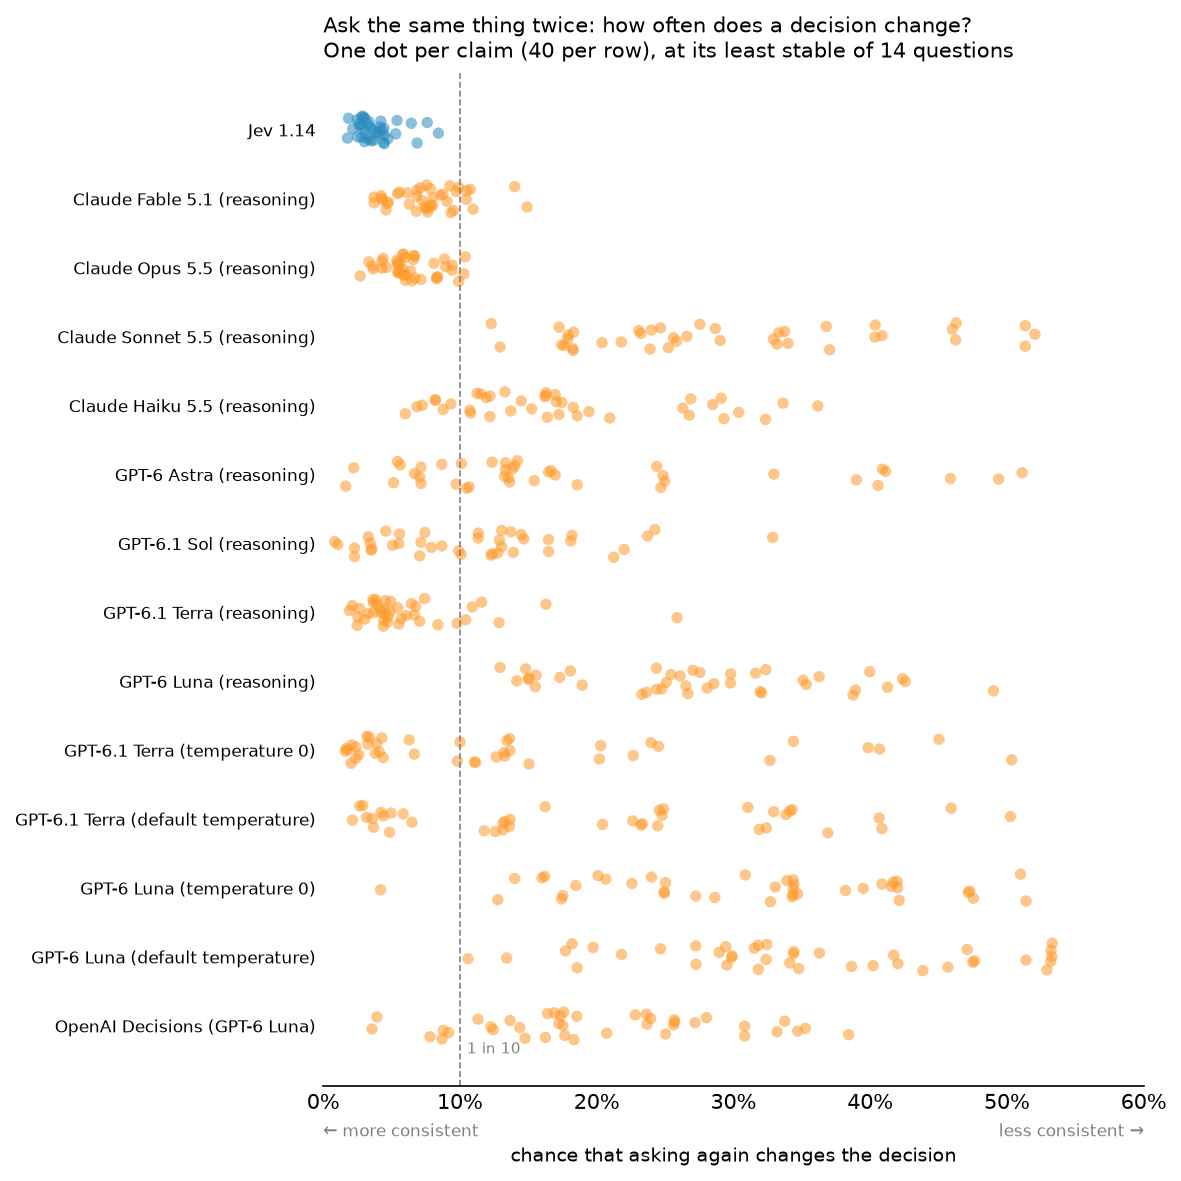

In [ ]:
STRIP_PALETTES = {
    "light": {"surface": "#ffffff", "ink": "#000000", "muted": "#808080", "jev": "#2b8cbe", "llm": "#fe9929", "alpha": 0.55},
    "dark": {"surface": "#0d0a0f", "ink": "#fafafa", "muted": "#a1a1aa", "jev": "#5fb0e0", "llm": "#fe9929", "alpha": 0.7},
}


def draw_strip(p: dict) -> plt.Figure:
    fig_strip, strip_ax = plt.subplots(figsize=(8, 0.5 * len(STRIP_ORDER) + 1), facecolor=p["surface"])
    strip_ax.set_facecolor(p["surface"])
    for position, label in enumerate(STRIP_ORDER):
        values = least_stable[label]
        # spread the claims vertically so dots with close values stay countable
        strip_ax.scatter(
            values,
            position + np.linspace(-0.2, 0.2, len(values)),
            s=30,
            alpha=p["alpha"],
            color=p["jev"] if label == TYPESAFE_LABEL else p["llm"],
            edgecolors="none",
        )
    strip_ax.axvline(0.10, color=p["muted"], linewidth=0.8, linestyle="--")
    strip_ax.text(0.105, len(STRIP_ORDER) - 0.55, "1 in 10", fontsize=7, color=p["muted"], va="bottom")
    strip_ax.set_yticks(range(len(STRIP_ORDER)), STRIP_ORDER, fontsize=8)
    strip_ax.invert_yaxis()  # first row on top
    strip_ax.set_xlim(0, 0.6)
    strip_ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    strip_ax.set_xlabel("chance that asking again changes the decision", fontsize=9, labelpad=16)
    for x, text, align in ((0, "← more consistent", "left"), (1, "less consistent →", "right")):
        # a fixed offset below the axis, so the labels sit above the x label at any height
        strip_ax.annotate(text, (x, 0), xycoords="axes fraction", xytext=(0, -18),
                          textcoords="offset points", ha=align, va="top", fontsize=8,
                          color=p["muted"])
    for edge in ("top", "right", "left"):
        strip_ax.spines[edge].set_visible(False)
    strip_ax.tick_params(length=0, labelcolor=p["ink"])
    strip_ax.spines["bottom"].set_color(p["ink"])
    strip_ax.xaxis.label.set_color(p["ink"])
    strip_ax.set_title(
        "Ask the same thing twice: how often does a decision change?\n"
        f"One dot per claim ({NUM_CLAIMS} per row), at its least stable of {len(QUESTIONS)} questions",
        loc="left",
        fontsize=10,
        color=p["ink"],
    )
    fig_strip.tight_layout()
    return fig_strip


# The docs build sets COOKSAFE_RENDER and also draws a dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig_strip = draw_strip(STRIP_PALETTES[theme])
    display(fig_strip, metadata={"theme": theme})
    plt.close(fig_strip)

## Open it in the TypeSafe playground

The link below opens the example claim and rubric in the playground: one claim, the same
14 `Noul` questions, and `jev-latest`. It omits the changing `uid` field used
above.

In [ ]:
playground_link = make_playground_link(
    {"claim": CLAIM},
    {key: Noul(instructions=question) for key, question in QUESTIONS.items()},
)
display(
    Markdown(
        f"🔗 [Open this claim + rubric in the TypeSafe playground]({playground_link})"
    )
)

🔗 [Open this claim + rubric in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiFADYCGAlnKQSSAA4TnVQCe9+jLbnAfWphupAIIAFALQB2GQBYAjAGZSAGnyk+7DgAtWYBACdRIAFKUkCfABEICdZpAIAZi4RQU1AG4O8TgCYABgCANikgxSlFAFZHUiwmaiMEAGdTYICZCKjY+LIIXyNKAHM07kYoVjZU6ggkbhQjGAQNUhTUSnIBFNoAIxgjVIREVG4XLuGAXzbwBDAYT2o+8j8CGKCggDog2aZjISQoYWQUATY4ahRuRU3NndmalHmBMCMfY3T-AG1SCytbPZ8mYILokIC-ABdWZYCgwWr1L4EX4gJqUKAAawA9FU4PsvF5fPg3j5qEgSvkSUVUvgkBAUPgnvN8PV8ChdNZtJxSNCnCkWEYvOSBAB3MmQEWvSgcJH4W57VjsBA9BACs4pACOMGSL0Kxm4wXuQRmTgoNDo-kqVFoQhE-lIAGEADIAWSkMQ2AQAnPkycdDKgpc8MiFwkFwgEABz5fkQQUvMCUYP2kCZMPZILySnvIqmEFgiGUtJQd5MLz1UxiFDPJCGMD4Shs4qYqSJjj4BC+VAAbnwvl07FW+BFlBpKUoRikyDr+D67cs9I5RnwUAn+DJbI5+FS+08Sbj+CYE4xZJKjPpw4HQ9SKCTdSQE44W3wADkL6z2dZjkZYFctvlKDgCAYEDM1aHmbhlACDYHicNgrCEZ44Flb5GCuEZTHHZcBjxYx8H5KgoBGU58iqG8bhkI0TTQpDTCPMkGQAanw1wyWoVJdFIiByP8SMqI0GiMJTI8jBPckpGGJBUgPFJVzYPpinLBoQFmMjrn8eQYONATSHQi0CHaU4uhXNcAApQmJaVUgASi4niCGUKjeVISBYFGW8lO4FF+RoZc0i8OAk2sUyJBsAAxWyVKcSNLMCspD30FBuJ5E1SEoMAACt4WeIwBDpZ4UMYSgYHZONTGKpKpCaahSj8WZ8rWJwHWqdj7xXPVini9FCQQZ8xCYJgjD1MBnwkaV8BcGByHIBsgJAhkABJlDUaCgjZCBD0VTh9HIQwjA0GJojWgZaisVIaTbVJ-xAKZnLIa04AEAcbzjLhLVIMDkPOUczkUAIgINPZ3jjV5kGoCD-GNKYpii5ghrxFBUgwbB-CID6OohhhSBQDh9lMOkpt9KSmkWJTZVIABJGlP3Pc72qKZkQL2zdOS2jgAHIaSqabWtZKoilqgB+UhUucTA4QRZSsdRXHGtIAnyCJm9miWRFTDsNIG02-h21hch4TaygBvIdsks3djadSYWbtmeoBG-X91OlnG8ZTBWlZJ1WpPV4QWfannJfwXQjf2cERSvawaf7QdrBHGk+gQU9iRzZAWXBGnmwQNFMXXRGEHIFxrdFutSeWVYKmx2X8eAxWot04mVbJ0wAHUa-rGmFo2NaS6WFZrAT9qjFklATYbY3wfrBOXDjaxLHbI8OGAlAi9mVzUgEVIYDcdhwbGd6ZddgyQHduuQDJZXS7VlMqb9pNbygDl61c+AjKU7ct5cHfTnWhtMpgMB2BBT9p9BsqQpDsRXk4MU7IyTnFoFcCuB85bHxrh7Ru95yYgBvjTQCwFUArgesyaBA505bn2JOP0Jx8H82MLVRk8Dl4i1mMQ2BYpawQBFIgl2yCT6zHPp7JuKYbC+xpuQbiNJoCwGXCw0hrMdacwbEsIkNDOqcmMHUMAkDDJqheAFfOb1nZVzdqg0+-D0FXyPs3UcfsxF01jPGesMi-Zcg5mOBAWodSOPFBwrRIAOi3m6PnagJQy6NUYNw6uhNTEN0vt7a+1Mtz+K6FIVcy41IdjYCEvuE0ZKJzgAMIYxF8FMzwjAmkLjfEuGKP-AQLgqAUn3hE4xUS+ExK9pgsQKQWZdPFIApKQxNxJmHBOYo+DGxVOKvWFI3hwYil8boeAlgVQzIQJwxpRij68KcGY2JmCrHlOlO5Meg1hqznnCVCAgVnjt3eHQ4hS8tYLMCuCdKWUbzGAUdM2ZvjnkwC6Ms2ZXCNlOC2fXC+7TTAAGV9BTXbs9Ah5pZzWCGiVZk09ly-K6FiTe5CZnSWXF81ZSL0WcmlEvXx8FlR6XXpvfSPBK6HxBSY1p4LBFHzsMAwh9ZKXgKQu1G8NJ0r1hgEwH+NMkoBNmnghkn15i+M3gpCAJQ7wVnWYy+WzLtltLZU4bBS5Z6bRrF4Loo8kxSAmFNBkMCjD1hEjjP259Bh4SqLCw8gxN7WHRe-RVyq36yQ6hwIuMMNAgCNtQAAap8e8qNvCKBukAA)